In [5]:
from pathlib import Path
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import pertpy as pt

- does each modality get all control inputs? Eg would the morphology change differently depending on the transcriptome control state?

# Data overview sciplex3 + 4i data with overlapping drug perturbations

## Overview 4i data from cellot
- 36 drug perturbations including 8 combinations
- we don't have raw 4i output, but a processed dataset with:
    - mean and sum intensity of each protein antibody for nucleus and whole cell (how were the cells segmented?)
    - morphology features
    - after clustering for morphology features --> protein signal does not distribute homogeneously, so we could have some connection and overlapp between the two modalities (even if we exclude DAPI) but also add-on value
    - [ ] calculate ratio to check for protein activity changes in the analysis --> potentially meaningful
    - [x] drug perturbation distributions don't completely overlapp --> two cell lines that can be distinguished by marker genes
    - citation from cellot: 'Additionally to the multiplexed information generated by 4i, cellular and nuclear morphology are routinely extracted from microscopy images (without the need for 4i) by image analysis algorithms73'
    - two melanoma cell lines, which can be distinguished by marker proteins: differences in marker expression30: 'the former a mesenchymal subtype (SOX9+, MelA-), the latter a melanocytic subtype (Sox9-, MelA+)' --> explains the subpopulations when looking at the intensity of the marker proteins, but interestingly, this somewhat aligns with the morphology clusters
    - [ ] check cl (=control?)
    

In [3]:
DATA_PATH = Path('/lustre/groups/ml01/workspace/multimodal_fm/data/cellot/datasets')

In [4]:
cellot_4i = sc.read_h5ad(DATA_PATH / '4i' / '8h.h5ad')
cellot_4i

AnnData object with n_obs × n_vars = 119479 × 78
    obs: 'drug'
    var: 'cell_part', 'measurement', 'stat', 'feature', 'original'
    uns: 'source'

In [6]:
cellot_4i.uns

{'source': '/cluster/work/tumorp/share/all_cohorts/deepdrugs/cellot/melanoma_timecourse/scdata_and_conditions_MelTimecourse2_8h_norm.csv'}

In [4]:
np.unique(cellot_4i.obs['drug'], return_counts=True)

(array(['cisplatin', 'cisplatin_olaparib', 'cl', 'control', 'crizotinib',
        'dabrafenib', 'dacarbazine', 'dasatinib', 'decitabine',
        'dexamethasone', 'erlotinib', 'everolimus', 'hydroxyurea',
        'imatinib', 'ixazomib', 'ixazomib_lenalidomide_dexamethasone',
        'lenalidomide', 'melphalan', 'midostaurin', 'mln2480', 'olaparib',
        'paclitaxel', 'palbociclib', 'panobinostat',
        'pomalidomide_carfilzomib_dexamethasone', 'regorafenib',
        'sec.abcl', 'sorafenib', 'staurosporine', 'temozolomide',
        'trametinib', 'trametinib_dabrafenib', 'trametinib_erlotinib',
        'trametinib_midostaurin', 'trametinib_panobinostat', 'ulixertinib',
        'vemurafenib_cobimetinib', 'vindesine'], dtype=object),
 array([ 2693,  2245, 18332, 10995,  1978,  2675,  2485,  2250,  2648,
         2796,  2406,  2592,  2715,  2631,  2514,  2522,  2524,  2352,
         2425,  2367,  2540,  2636,  2322,  2492,  2545,  2524,  3399,
         2763,  1310,  2513,  2637,  2958

In [6]:
cellot_4i.var

,cell_part,measurement,stat,feature,original
index,,,,,
morphology-nuclei-area,nuclei,morphology,NaN,area,Nuclei_Morphology_Area
morphology-nuclei-circularity,nuclei,morphology,NaN,circularity,Nuclei_Morphology_Circularity
morphology-nuclei-convexity,nuclei,morphology,NaN,convexity,Nuclei_Morphology_Convexity
morphology-nuclei-eccentricity,nuclei,morphology,NaN,eccentricity,Nuclei_Morphology_Eccentricity
morphology-nuclei-elongation,nuclei,morphology,NaN,elongation,Nuclei_Morphology_Elongation
...,...,...,...,...,...
intensity-cell-CD45-sum,cell,intensity,sum,CD45,Intensity_sum_CD45
intensity-cell-ClCasp3-mean,cell,intensity,mean,ClCasp3,Intensity_mean_ClCasp3
intensity-cell-ClCasp3-sum,cell,intensity,sum,ClCasp3,Intensity_sum_ClCasp3


In [ ]:
cellot_4i.var.index

Index(['morphology-nuclei-area', 'morphology-nuclei-circularity',
       'morphology-nuclei-convexity', 'morphology-nuclei-eccentricity',
       'morphology-nuclei-elongation', 'morphology-nuclei-equivalent_diameter',
       'morphology-nuclei-extent', 'morphology-nuclei-major_axis_length',
       'morphology-nuclei-mean_radius', 'morphology-nuclei-perimeter',
       'morphology-nuclei-roundness', 'morphology-cell-area',
       'morphology-cell-perimeter', 'morphology-cell-eccentricity',
       'morphology-cell-extent', 'morphology-cell-convexity',
       'morphology-cell-circularity', 'morphology-cell-roundness',
       'morphology-cell-elongation', 'morphology-cell-equivalent_diameter',
       'morphology-cell-major_axis_length', 'morphology-cell-mean_radius',
       'intensity-nuclei-DAPI-mean', 'intensity-nuclei-DAPI-sum',
       'intensity-nuclei-MelA-mean', 'intensity-nuclei-MelA-sum',
       'intensity-nuclei-Sox9-mean', 'intensity-nuclei-Sox9-sum',
       'intensity-nuclei-pS6k

In [ ]:
features_h5ad = set([
    'morphology-nuclei-area', 'morphology-nuclei-circularity',
    'morphology-nuclei-convexity', 'morphology-nuclei-eccentricity',
    'morphology-nuclei-elongation', 'morphology-nuclei-equivalent_diameter',
    'morphology-nuclei-extent', 'morphology-nuclei-major_axis_length',
    'morphology-nuclei-mean_radius', 'morphology-nuclei-perimeter',
    'morphology-nuclei-roundness', 'morphology-cell-area',
    'morphology-cell-perimeter', 'morphology-cell-eccentricity',
    'morphology-cell-extent', 'morphology-cell-convexity',
    'morphology-cell-circularity', 'morphology-cell-roundness',
    'morphology-cell-elongation', 'morphology-cell-equivalent_diameter',
    'morphology-cell-major_axis_length', 'morphology-cell-mean_radius',
    'intensity-nuclei-DAPI-mean', 'intensity-nuclei-DAPI-sum',
    'intensity-nuclei-MelA-mean', 'intensity-nuclei-MelA-sum',
    'intensity-nuclei-Sox9-mean', 'intensity-nuclei-Sox9-sum',
    'intensity-nuclei-pS6k1-mean', 'intensity-nuclei-pS6k1-sum',
    'intensity-nuclei-PCNA-mean', 'intensity-nuclei-PCNA-sum',
    'intensity-nuclei-pAKT-mean', 'intensity-nuclei-pAKT-sum',
    'intensity-nuclei-pEGFR-mean', 'intensity-nuclei-pEGFR-sum',
    'intensity-nuclei-aTUB-mean', 'intensity-nuclei-aTUB-sum',
    'intensity-nuclei-pERK-mean', 'intensity-nuclei-pERK-sum',
    'intensity-nuclei-Ki67-mean', 'intensity-nuclei-Ki67-sum',
    'intensity-nuclei-pMET-mean', 'intensity-nuclei-pMET-sum',
    'intensity-nuclei-CD45-mean', 'intensity-nuclei-CD45-sum',
    'intensity-nuclei-ClCasp3-mean', 'intensity-nuclei-ClCasp3-sum',
    'intensity-nuclei-TotProtein-mean', 'intensity-nuclei-TotProtein-sum',
    'intensity-cell-DAPI-mean', 'intensity-cell-DAPI-sum',
    'intensity-cell-MelA-mean', 'intensity-cell-MelA-sum',
    'intensity-cell-Sox9-mean', 'intensity-cell-Sox9-sum',
    'intensity-cell-pS6k1-mean', 'intensity-cell-pS6k1-sum',
    'intensity-cell-PCNA-mean', 'intensity-cell-PCNA-sum',
    'intensity-cell-pAKT-mean', 'intensity-cell-pAKT-sum',
    'intensity-cell-pEGFR-mean', 'intensity-cell-pEGFR-sum',
    'intensity-cell-aTUB-mean', 'intensity-cell-aTUB-sum',
    'intensity-cell-pERK-mean', 'intensity-cell-pERK-sum',
    'intensity-cell-Ki67-mean', 'intensity-cell-Ki67-sum',
    'intensity-cell-pMET-mean', 'intensity-cell-pMET-sum',
    'intensity-cell-CD45-mean', 'intensity-cell-CD45-sum',
    'intensity-cell-ClCasp3-mean', 'intensity-cell-ClCasp3-sum',
    'intensity-cell-TotProtein-mean', 'intensity-cell-TotProtein-sum']
)

features_file = set([
    "intensity-cell-CD45-mean",
    "intensity-cell-ClCasp3-mean",
    "intensity-cell-DAPI-sum",
    "intensity-cell-Ki67-mean",
    "intensity-cell-MelA-mean",
    "intensity-cell-PCNA-mean",
    "intensity-cell-Sox9-mean",
    "intensity-cell-aTUB-mean",
    "intensity-cell-pAKT-mean",
    "intensity-cell-pEGFR-mean",
    "intensity-cell-pERK-mean",
    "intensity-cell-pMET-mean",
    "intensity-cell-pS6k1-mean",
    "intensity-nuclei-CD45-mean",
    "intensity-nuclei-ClCasp3-mean",
    "intensity-nuclei-DAPI-sum",
    "intensity-nuclei-Ki67-mean",
    "intensity-nuclei-MelA-mean",
    "intensity-nuclei-PCNA-mean",
    "intensity-nuclei-Sox9-mean",
    "intensity-nuclei-aTUB-mean",
    "intensity-nuclei-pAKT-mean",
    "intensity-nuclei-pEGFR-mean",
    "intensity-nuclei-pERK-mean",
    "intensity-nuclei-pMET-mean",
    "intensity-nuclei-pS6k1-mean",
    "morphology-cell-area",
    "morphology-cell-circularity",
    "morphology-cell-convexity",
    "morphology-cell-eccentricity",
    "morphology-cell-elongation",
    "morphology-cell-equivalent_diameter",
    "morphology-cell-extent",
    "morphology-cell-major_axis_length",
    "morphology-cell-mean_radius",
    "morphology-cell-perimeter",
    "morphology-cell-roundness",
    "morphology-nuclei-area",
    "morphology-nuclei-circularity",
    "morphology-nuclei-convexity",
    "morphology-nuclei-eccentricity",
    "morphology-nuclei-elongation",
    "morphology-nuclei-equivalent_diameter",
    "morphology-nuclei-extent",
    "morphology-nuclei-major_axis_length",
    "morphology-nuclei-mean_radius",
    "morphology-nuclei-perimeter",
    "morphology-nuclei-roundness"
])

In [ ]:
features_h5ad - features_file

{'intensity-cell-CD45-sum',
 'intensity-cell-ClCasp3-sum',
 'intensity-cell-DAPI-mean',
 'intensity-cell-Ki67-sum',
 'intensity-cell-MelA-sum',
 'intensity-cell-PCNA-sum',
 'intensity-cell-Sox9-sum',
 'intensity-cell-TotProtein-mean',
 'intensity-cell-TotProtein-sum',
 'intensity-cell-aTUB-sum',
 'intensity-cell-pAKT-sum',
 'intensity-cell-pEGFR-sum',
 'intensity-cell-pERK-sum',
 'intensity-cell-pMET-sum',
 'intensity-cell-pS6k1-sum',
 'intensity-nuclei-CD45-sum',
 'intensity-nuclei-ClCasp3-sum',
 'intensity-nuclei-DAPI-mean',
 'intensity-nuclei-Ki67-sum',
 'intensity-nuclei-MelA-sum',
 'intensity-nuclei-PCNA-sum',
 'intensity-nuclei-Sox9-sum',
 'intensity-nuclei-TotProtein-mean',
 'intensity-nuclei-TotProtein-sum',
 'intensity-nuclei-aTUB-sum',
 'intensity-nuclei-pAKT-sum',
 'intensity-nuclei-pEGFR-sum',
 'intensity-nuclei-pERK-sum',
 'intensity-nuclei-pMET-sum',
 'intensity-nuclei-pS6k1-sum'}

In [ ]:
cellot_4i.obs

,drug
no3l3q9j,ixazomib
ge649mxa,ixazomib
esl7vk2y,ixazomib
wjw29d3z,ixazomib
zb9fc7by,ixazomib
...,...
wlb7mtqb,cl
7rocq3r7,cl
87x7p4jo,cl
k2u4vwg7,cl


In [8]:
adata = cellot_4i
control = ['control', 'cl']

adata_control = adata[adata.obs['drug'].isin(control)].copy()

morphology_features = [idx for idx in adata_control.var.index if idx.startswith("morphology-")]
dapi_features = [idx for idx in adata_control.var.index if "DAPI" in idx and idx.startswith("intensity")]
combined_features = morphology_features + dapi_features

intensity_features = [
    var for var in adata_control.var.index
    if var.startswith("intensity") and 'mean' in var
]

adata_control_morphology = adata_control[:,combined_features].copy()

adata_control_morphology.layers['normalized_counts'] = StandardScaler().fit_transform(adata_control_morphology.X)
adata_control_morphology.layers['counts'] = adata_control_morphology.X
adata_control_morphology.X = adata_control_morphology.layers['normalized_counts']
sc.tl.pca(adata_control_morphology, n_comps=10)

adata_control.uns['morphology_pca'] = adata_control_morphology.uns['pca']
adata_control.obsm['X_morphology_pca'] = adata_control_morphology.obsm['X_pca']

sc.pp.neighbors(adata_control, use_rep='X_morphology_pca', key_added='morphology_neighbors')
sc.tl.leiden(adata_control, key_added='morphology_leiden', neighbors_key='morphology_neighbors')
sc.tl.umap(adata_control, neighbors_key='morphology_neighbors')


/lustre/groups/ml01/workspace/lea.zimmermann/software/miniconda3/envs/mmfm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_4090380/17200956.py:26: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_control, key_added='morphology_leiden', neighbors_key='morphology_neighbors')


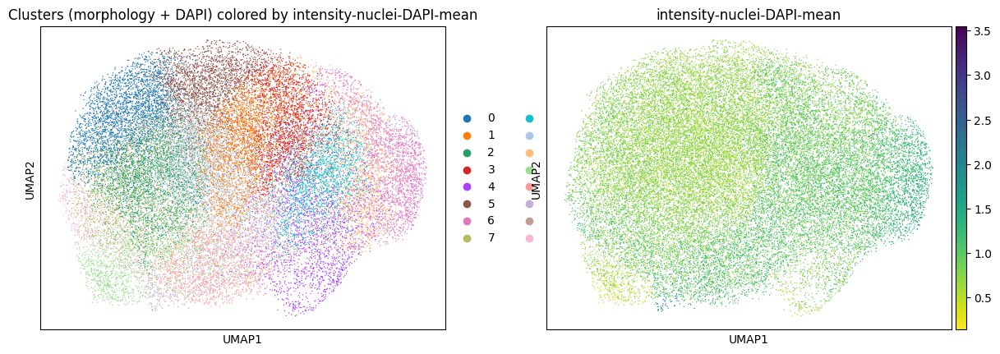

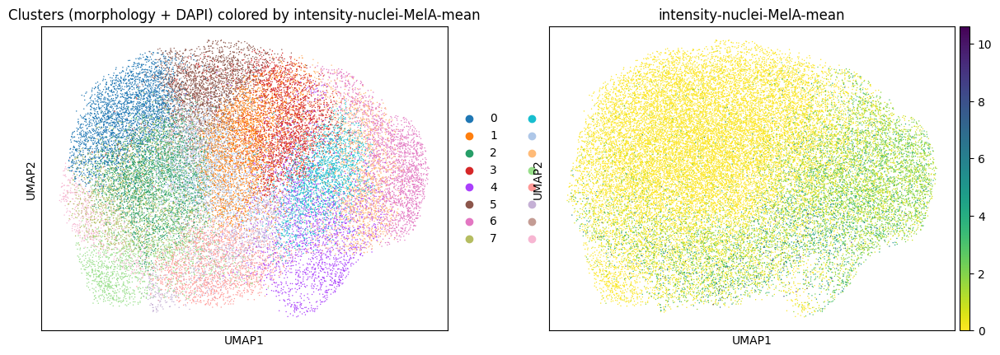

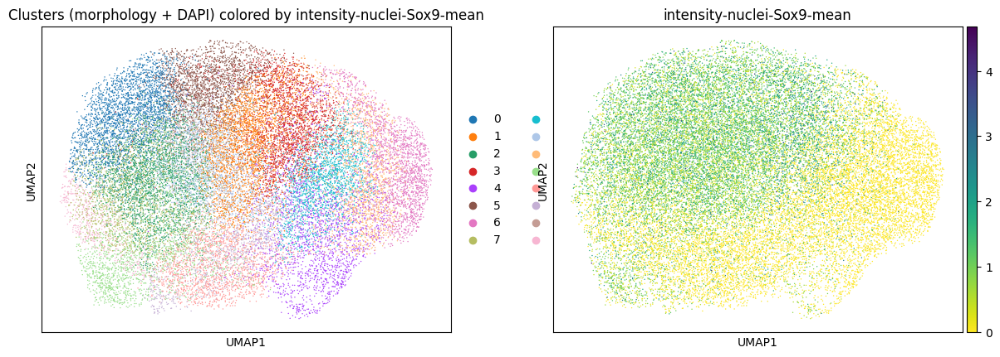

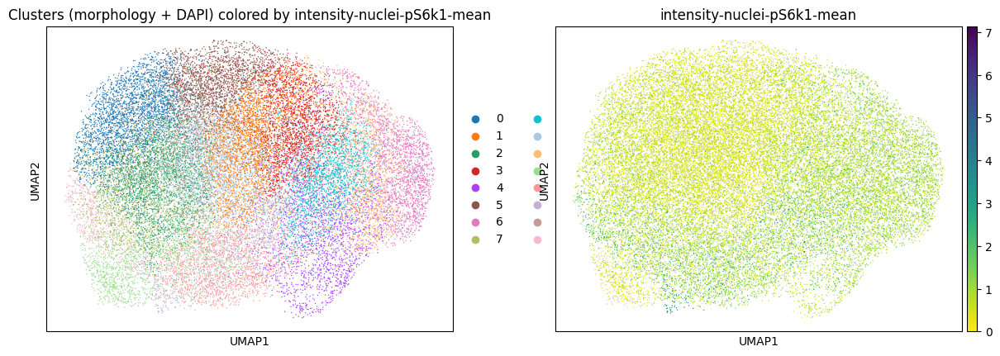

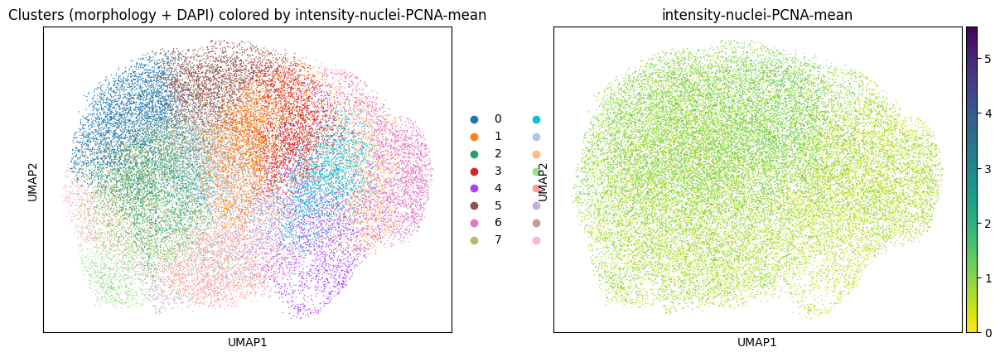

...

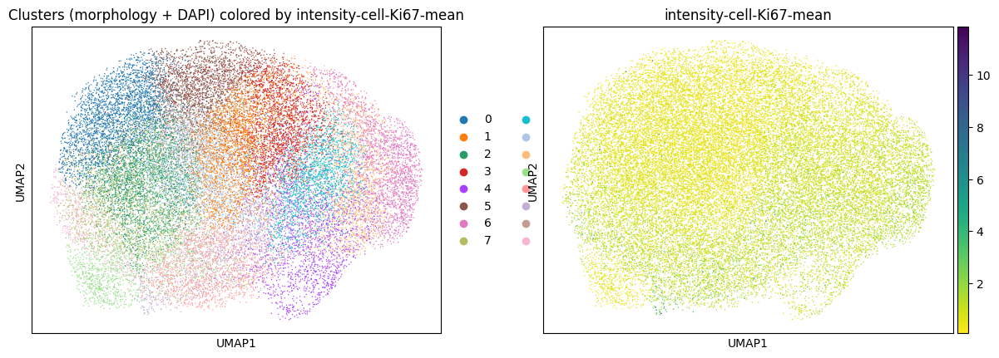

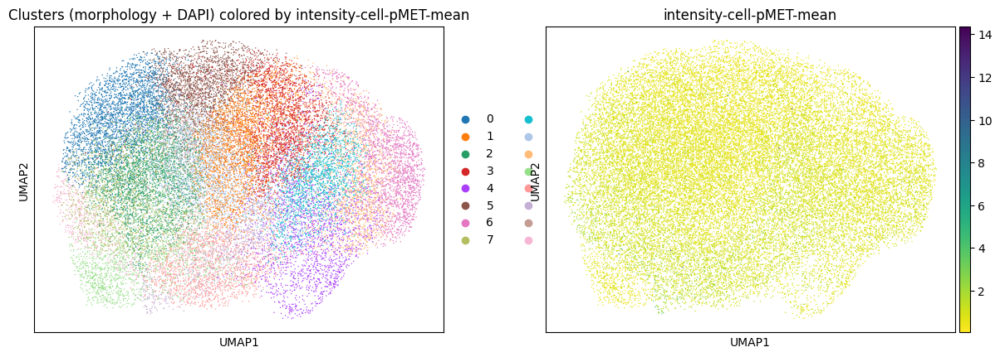

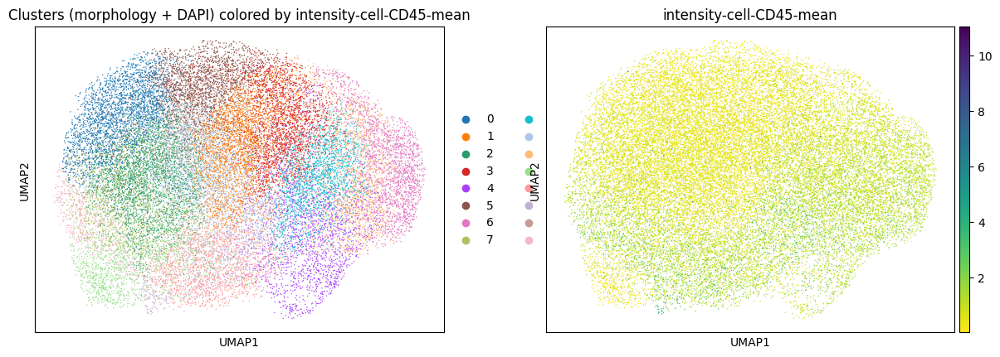

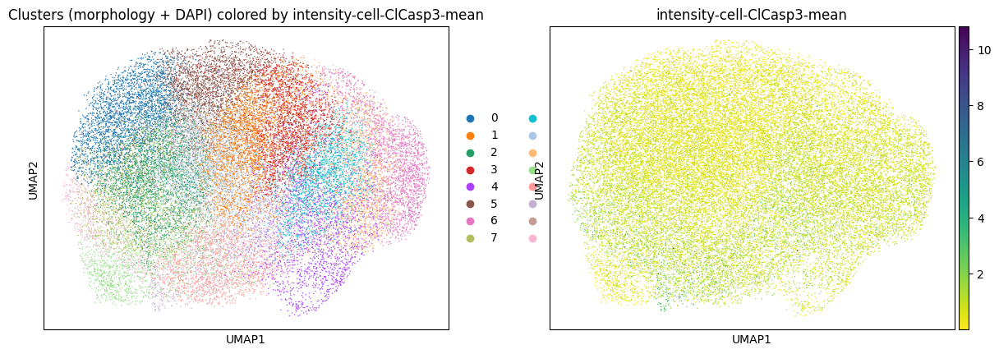

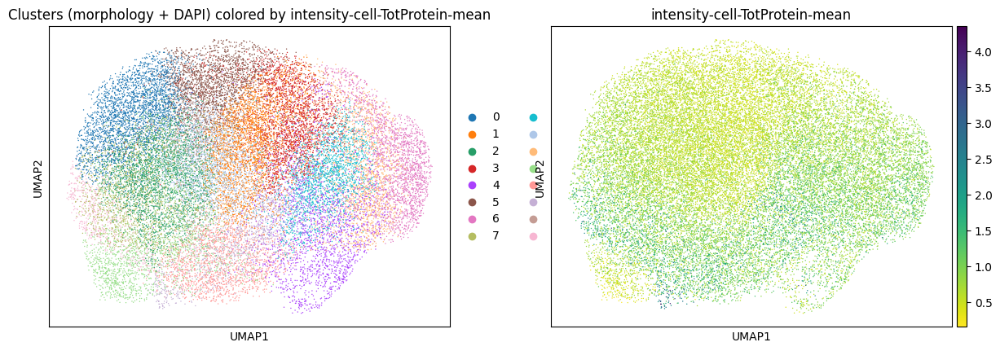

In [12]:
for feature in intensity_features:
    sc.pl.umap(
        adata_control,
        color=['morphology_leiden', feature],
        title=f'Clusters (morphology + DAPI) colored by {feature}',
        show=False,
        cmap='viridis_r'
    )
    plt.show()

TODO: instead look at the ratio of nucleus to cytoplasm

In [13]:
adata_control.var
# ratio = intensity-nuclei-PROTEIN-mean / intensity-cell-PROTEIN-mean


,cell_part,measurement,stat,feature,original
index,,,,,
morphology-nuclei-area,nuclei,morphology,NaN,area,Nuclei_Morphology_Area
morphology-nuclei-circularity,nuclei,morphology,NaN,circularity,Nuclei_Morphology_Circularity
morphology-nuclei-convexity,nuclei,morphology,NaN,convexity,Nuclei_Morphology_Convexity
morphology-nuclei-eccentricity,nuclei,morphology,NaN,eccentricity,Nuclei_Morphology_Eccentricity
morphology-nuclei-elongation,nuclei,morphology,NaN,elongation,Nuclei_Morphology_Elongation
...,...,...,...,...,...
intensity-cell-CD45-sum,cell,intensity,sum,CD45,Intensity_sum_CD45
intensity-cell-ClCasp3-mean,cell,intensity,mean,ClCasp3,Intensity_mean_ClCasp3
intensity-cell-ClCasp3-sum,cell,intensity,sum,ClCasp3,Intensity_sum_ClCasp3


/lustre/groups/ml01/workspace/lea.zimmermann/software/miniconda3/envs/mmfm/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:438: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  warn(msg, FutureWarning)
/lustre/groups/ml01/workspace/lea.zimmermann/software/miniconda3/envs/mmfm/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:379: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = X_pca


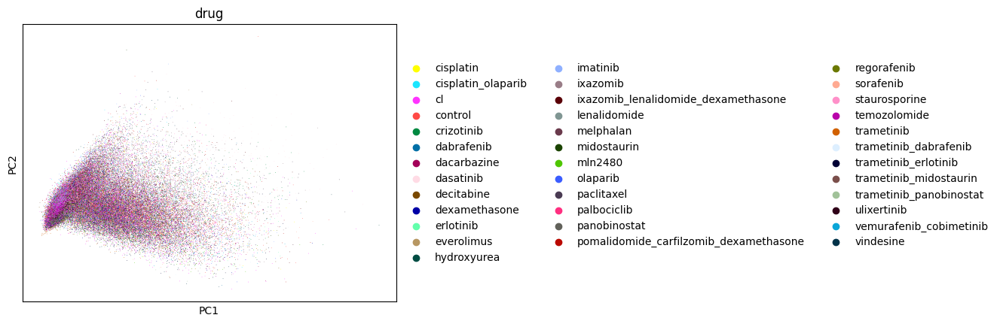

In [16]:
adata = adata[adata.obs['drug'] != 'sec.abcl']

sc.pp.pca(adata, n_comps=10, use_highly_variable=False)
sc.pl.pca(adata, color='drug')

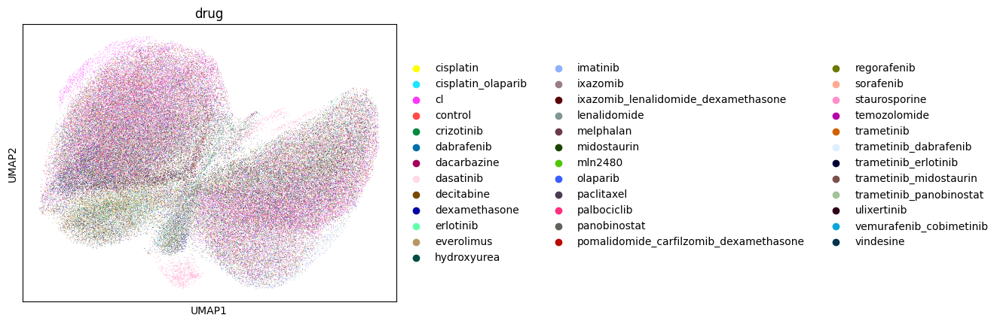

In [17]:
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.pl.umap(adata, color='drug')

In [23]:
adata_singles = adata[~adata.obs['drug'].str.contains('_')].copy()

/lustre/groups/ml01/workspace/lea.zimmermann/software/miniconda3/envs/mmfm/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:438: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  warn(msg, FutureWarning)


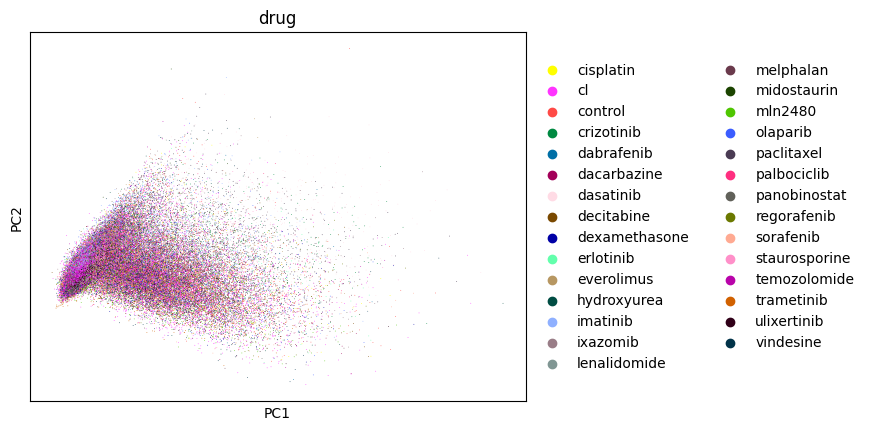

In [24]:
sc.pp.pca(adata_singles, n_comps=10, use_highly_variable=False)
sc.pl.pca(adata_singles, color='drug')

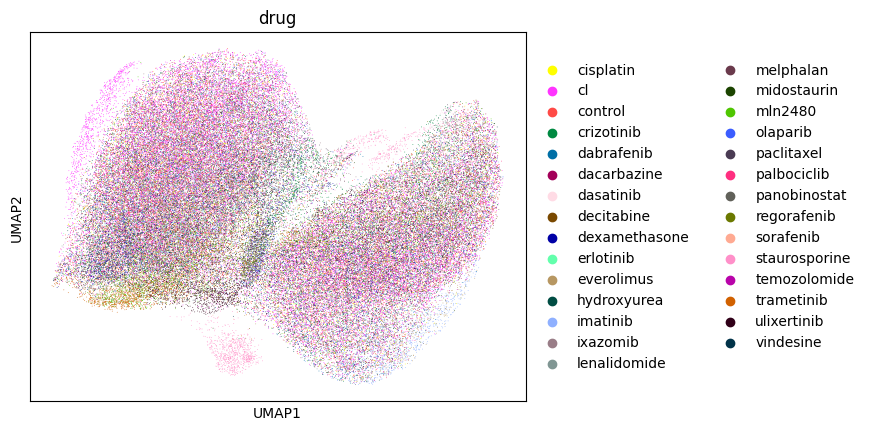

In [25]:
sc.pp.neighbors(adata_singles)
sc.tl.umap(adata_singles)
sc.pl.umap(adata_singles, color='drug')

## Overview sciplex3 + 4i data with overlapping drug perturbations

- 189 drugs including control (combinations??)
- but only 9 drugs overlap with the 4i dataset
    - drug effects in this smaller dataset seem to be also less pronounced, as cell line and dosages introduce higher variability --> [ ] would need more quantification if interesting
    - 4i dataset uses 'mixture of two melanoma tumor cell lines (M130219 and M130429)', but in sciplex MCF7, A549 & K562
    - [ ] so far unclear which dose was used to treat the 4i dataset --> might reduce the size of sciplex even further

In [5]:
sciplex = pt.data.sciplex3_raw()

In [3]:
sciplex

AnnData object with n_obs × n_vars = 581777 × 58347
    obs: 'cell_type', 'dose', 'dose_character', 'dose_pattern', 'g1s_score', 'g2m_score', 'pathway', 'pathway_level_1', 'pathway_level_2', 'product_dose', 'product_name', 'proliferation_index', 'replicate', 'size_factor', 'target', 'vehicle'
    var: 'id', 'num_cells_expressed-0-0', 'num_cells_expressed-1-0', 'num_cells_expressed-1'

In [ ]:
CDDP, cis-DDP, Cis-Diamminedichloroplatinum, 
cis-Diamminedichloroplatinum (II), Cis-platin, cisplatinum, 
cis-Platinum, DDP, Peyrone's Chloride, Platinum Diamminodichloride,
Diaminedichloroplatinum

CAS-15663-27-1
NCI-c55776
NIOSH TP 2450000
NSC-119875
NK 801

Abiplatin (Netherlands), Cisplatin (UK), Cisplatyl (France),
Citoplatino (Italy), Lederplatin (Sweden), Neoplatin (Spain),
Norplatin (South Africa), Placis (Spain), Platamine (Australia),
Platiblastin (Germany), Platiblastine (Switzerland), Platinex
(Germany, Italy), Platinol (Canada), Plastistil (Spain), Platistin
(Sweden), Platosin (Netherlands), Pronto Platamine (Italy), Randa
(Japan)

In [ ]:
dexamethasone

Decaject
Decaject L.A.
Decaject-L.A.
Decameth
Decaspray
Dexamethasone
Dexasone
Dexpak
Hexadecadrol
Hexadrol
Maxidex
Methylfluorprednisolone
Millicorten
Oradexon 

In [5]:
np.unique(sciplex.obs['product_name'], return_counts=True)

(array(['(+)-JQ1', '2-Methoxyestradiol (2-MeOE2)', 'A-366', 'ABT-737',
        'AC480 (BMS-599626)', 'AG-14361', 'AG-490 (Tyrphostin B42)',
        'AICAR (Acadesine)', 'AMG-900', 'AR-42', 'AT9283', 'AZ 960',
        'AZD1480', 'Abexinostat (PCI-24781)',
        'Alendronate sodium trihydrate', 'Alisertib (MLN8237)',
        'Altretamine', 'Alvespimycin (17-DMAG) HCl', 'Aminoglutethimide ',
        'Amisulpride', 'Anacardic Acid', 'Andarine',
        'Aurora A Inhibitor I', 'Avagacestat (BMS-708163)', 'Azacitidine ',
        'BMS-265246', 'BMS-536924', 'BMS-754807', 'BMS-911543', 'BRD4770',
        'Barasertib (AZD1152-HQPA)', 'Baricitinib (LY3009104, INCB028050)',
        'Belinostat (PXD101)',
        'Bisindolylmaleimide IX (Ro 31-8220 Mesylate)',
        'Bosutinib (SKI-606)', 'Busulfan ', 'CEP-33779', 'CUDC-101',
        'CUDC-907', 'CYC116', 'Capecitabine ', 'Carmofur',
        'Cediranib (AZD2171)', 'Celecoxib',
        'Cerdulatinib (PRT062070, PRT2070)', 'Cimetidine ', 'Clevud

In [6]:
list1_to_list2_mapping = {
    'Crizotinib (PF-02341066)': 'crizotinib',
    'Dasatinib': 'dasatinib',
    'Decitabine': 'decitabine',
    'Lenalidomide (CC-5013)': 'lenalidomide',
    'Panobinostat (LBH589)': 'panobinostat',
    'Regorafenib (BAY 73-4506)': 'regorafenib',
    'Sorafenib Tosylate': 'sorafenib',
    'Trametinib (GSK1120212)': 'trametinib',
    'Olaparib': 'olaparib',
    'Baricitinib (LY3009104, INCB028050)': 'baricitinib',  # not in list 2, but related
    'Erlotinib': 'erlotinib',  # assuming implied
    'Dabrafenib': 'dabrafenib',
    'Midostaurin': 'midostaurin',
    'Temozolomide': 'temozolomide',
    'Palbociclib': 'palbociclib',
    'Paclitaxel': 'paclitaxel',
    'Staurosporine': 'staurosporine',
    'Vehicle': 'control',
    # 'Veliparib (ABT-888)': 'olaparib',  # same target (PARP), map to representative
    # 'Thalidomide': 'pomalidomide_carfilzomib_dexamethasone',  # mechanistically related
    # 'Alisertib (MLN8237)': 'mln2480',  # best guess, confirm in metadata if needed
    'Ixazomib': 'ixazomib',
    # 'Ixazomib_lenalidomide_dexamethasone': 'ixazomib_lenalidomide_dexamethasone',
}


In [7]:
sciplex.obs['drug'] = sciplex.obs['product_name'].map(list1_to_list2_mapping)

In [8]:
sciplex

AnnData object with n_obs × n_vars = 581777 × 58347
    obs: 'cell_type', 'dose', 'dose_character', 'dose_pattern', 'g1s_score', 'g2m_score', 'pathway', 'pathway_level_1', 'pathway_level_2', 'product_dose', 'product_name', 'proliferation_index', 'replicate', 'size_factor', 'target', 'vehicle', 'drug'
    var: 'id', 'num_cells_expressed-0-0', 'num_cells_expressed-1-0', 'num_cells_expressed-1'

In [9]:
scRNA = sciplex[~sciplex.obs['drug'].isna(),:].copy()

In [19]:
scRNA.obs

,cell_type,dose,dose_character,dose_pattern,g1s_score,g2m_score,pathway,pathway_level_1,pathway_level_2,product_dose,product_name,proliferation_index,replicate,size_factor,target,vehicle,drug
index,,,,,,,,,,,,,,,,,
A01_E09_RT_BC_101_Lig_BC_109-0-0,A549,0.0,0,3,0.000000,0.000000,Vehicle,Vehicle,Vehicle,Vehicle_0,Vehicle,0.000000,rep1,0.516561,Vehicle,1,control
A01_E09_RT_BC_101_Lig_BC_229-0-0,A549,10.0,10,4,1.817254,2.801225,Apoptosis,Protein folding & Protein degradation,E3 ubiquitin ligase activity,Lenalidomide (CC-5013)_10,Lenalidomide (CC-5013),3.073606,rep2,0.387978,TNF-alpha,0,lenalidomide
A01_E09_RT_BC_10_Lig_BC_324-0-0,A549,100.0,100,3,1.003658,2.806639,Protein Tyrosine Kinase,Tyrosine kinase signaling,RTK activity,Regorafenib (BAY 73-4506)_100,Regorafenib (BAY 73-4506),2.905941,rep2,1.157244,"c-RET,VEGFR",0,regorafenib
A01_E09_RT_BC_115_Lig_BC_90-0-0,A549,1000.0,1000,2,0.000000,0.987272,Protein Tyrosine Kinase,Tyrosine kinase signaling,RTK activity,Crizotinib (PF-02341066)_1000,Crizotinib (PF-02341066),0.987272,rep2,0.593859,"ALK,c-Met",0,crizotinib
A01_E09_RT_BC_116_Lig_BC_180-0-0,A549,1000.0,1000,2,1.608312,1.298259,Epigenetics,Epigenetic regulation,Histone deacetylation,Panobinostat (LBH589)_1000,Panobinostat (LBH589),2.035658,rep1,1.502114,HDAC,0,panobinostat
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
H12_F10_RT_BC_75_Lig_BC_115-1,K562,0.0,0,3,2.154430,1.066690,NA,Vehicle,Vehicle,Vehicle_0,Vehicle,2.354107,rep1,0.524729,NA,1,control
H12_F10_RT_BC_76_Lig_BC_174-1,K562,100.0,100,3,0.680545,0.680545,Epigenetics,Epigenetic regulation,Histone deacetylation,Panobinostat (LBH589)_100,Panobinostat (LBH589),1.081773,rep1,1.025690,HDAC,0,panobinostat
H12_F10_RT_BC_78_Lig_BC_67-1,K562,1000.0,1000,2,2.081763,0.694474,Protein Tyrosine Kinase,Tyrosine kinase signaling,RTK activity,Regorafenib (BAY 73-4506)_1000,Regorafenib (BAY 73-4506),2.199582,rep2,0.997351,"c-RET,VEGFR",0,regorafenib


In [11]:
scRNA

AnnData object with n_obs × n_vars = 38286 × 58347
    obs: 'cell_type', 'dose', 'dose_character', 'dose_pattern', 'g1s_score', 'g2m_score', 'pathway', 'pathway_level_1', 'pathway_level_2', 'product_dose', 'product_name', 'proliferation_index', 'replicate', 'size_factor', 'target', 'vehicle', 'drug'
    var: 'id', 'num_cells_expressed-0-0', 'num_cells_expressed-1-0', 'num_cells_expressed-1'

In [12]:
scRNA.obs['drug'].unique()

array(['control', 'lenalidomide', 'regorafenib', 'crizotinib',
       'panobinostat', 'sorafenib', 'baricitinib', 'trametinib',
       'decitabine', 'dasatinib'], dtype=object)

/lustre/groups/ml01/workspace/lea.zimmermann/software/miniconda3/envs/mmfm/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:438: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  warn(msg, FutureWarning)


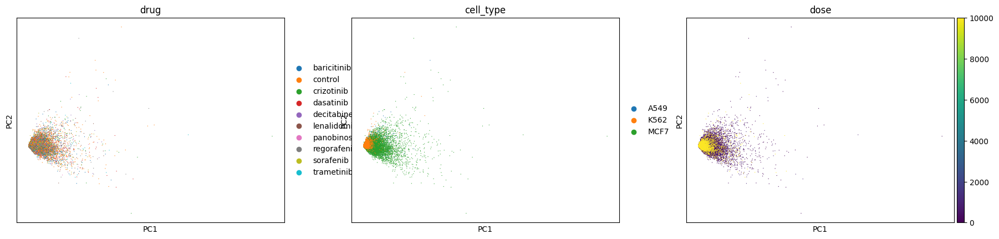

In [20]:
sc.pp.pca(scRNA, n_comps=300, use_highly_variable=False)
sc.pl.pca(scRNA, color=['drug', 'cell_type', 'dose'])

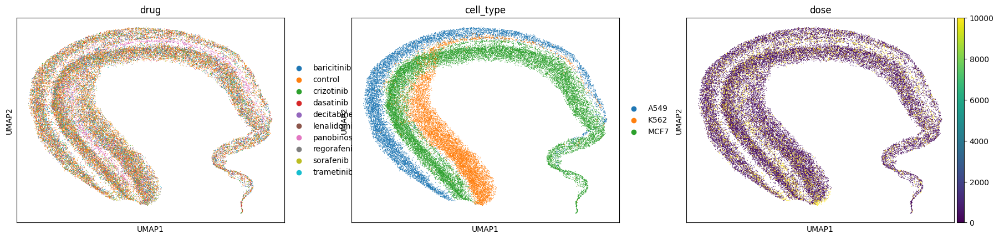

In [21]:
sc.pp.neighbors(scRNA)
sc.tl.umap(scRNA)
sc.pl.umap(scRNA, color=['drug', 'cell_type', 'dose'])

## Conclusion:

- might be hard to use scRNA and 4i dataset in combination because of low bio overlapp and drastical reduction of the sample size
- we could discuss using morphology and 4i imaging as two different modalities
    - they are, but need to check how they are entangled and check the protein markers and they bio meaning
    - there seems to be at least some signal --> check that this is not only due to the two cell lines and their markers as well as their morphological differences
    - we see perturbation effects in both cell lines after drug treatment, even though some of the drugs seem to have only small effects
    - [ ] check whether there are individual features that explain the r2 scores and then decide whether it makes sense to model this data
    - [ ] if modelling: we can either provide the model with a cell_line label or try to learn the perturbation effects and sox9 and mela expression simultaneously --> would that be an interesting use case to be able to calculate the shift and comare between the two cell_lines?
    - [ ] check Tahoe
    - [ ] check drug for double positive

For a first quick and dirty split of the two cell lines, we'll plot the distribution of Sox9 and MelA expression and try to find a suitable threshold:

In [6]:
cellot_4i.var

,cell_part,measurement,stat,feature,original
index,,,,,
morphology-nuclei-area,nuclei,morphology,NaN,area,Nuclei_Morphology_Area
morphology-nuclei-circularity,nuclei,morphology,NaN,circularity,Nuclei_Morphology_Circularity
morphology-nuclei-convexity,nuclei,morphology,NaN,convexity,Nuclei_Morphology_Convexity
morphology-nuclei-eccentricity,nuclei,morphology,NaN,eccentricity,Nuclei_Morphology_Eccentricity
morphology-nuclei-elongation,nuclei,morphology,NaN,elongation,Nuclei_Morphology_Elongation
...,...,...,...,...,...
intensity-cell-CD45-sum,cell,intensity,sum,CD45,Intensity_sum_CD45
intensity-cell-ClCasp3-mean,cell,intensity,mean,ClCasp3,Intensity_mean_ClCasp3
intensity-cell-ClCasp3-sum,cell,intensity,sum,ClCasp3,Intensity_sum_ClCasp3


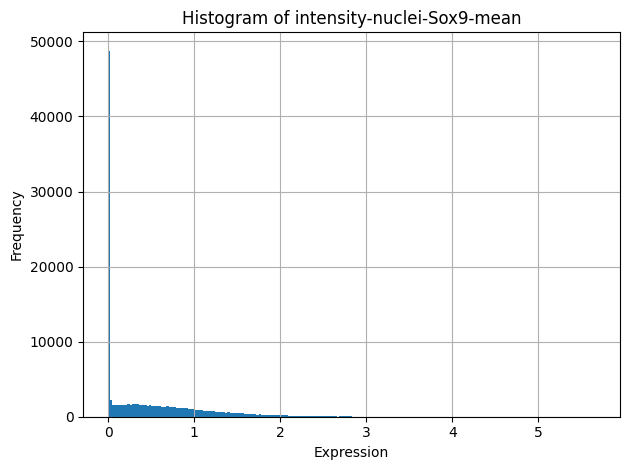

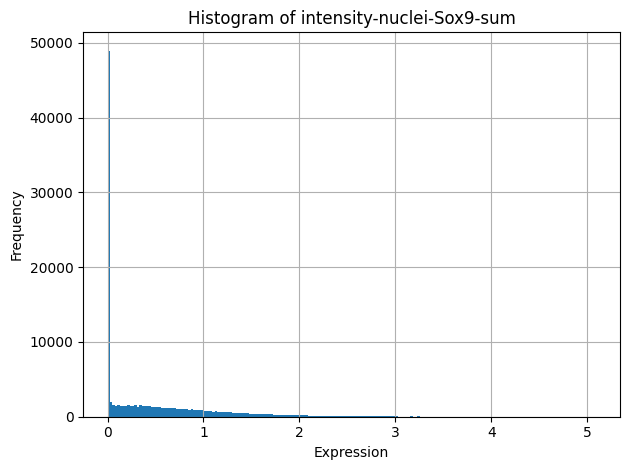

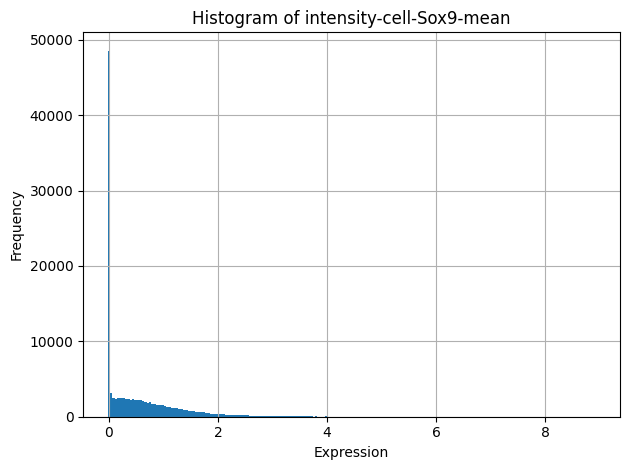

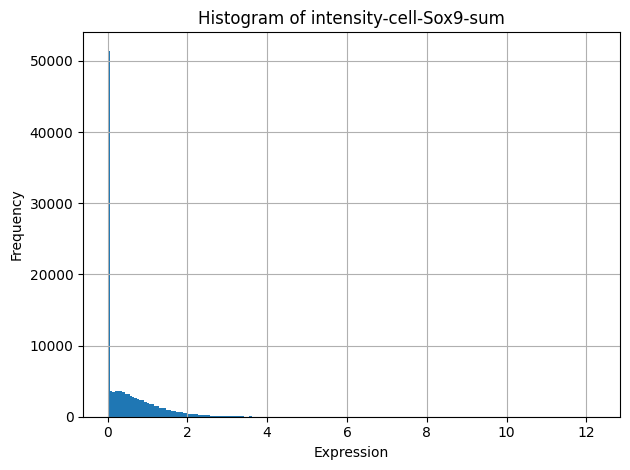

In [9]:
import matplotlib.pyplot as plt
import scanpy as sc

# Filter for features containing "Sox9"
sox9_features = [name for name in cellot_4i.var_names if "Sox9" in name]

# Plot histograms for each feature
for feature in sox9_features:
    plt.figure()
    plt.hist(cellot_4i[:, feature].X.A.flatten() if hasattr(cellot_4i[:, feature].X, 'A') else cellot_4i[:, feature].X.flatten(), bins=200)
    plt.title(f'Histogram of {feature}')
    plt.xlabel('Expression')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


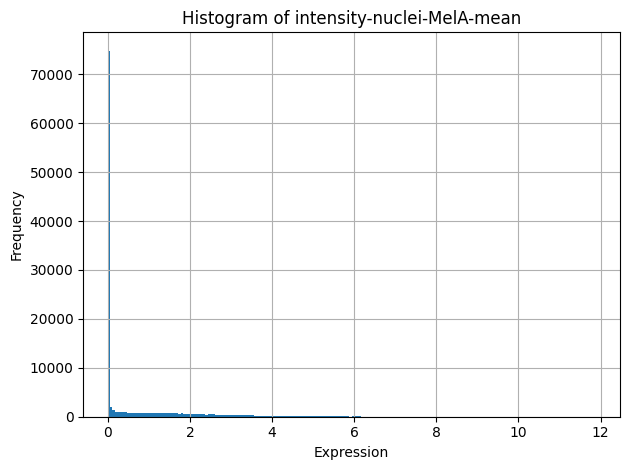

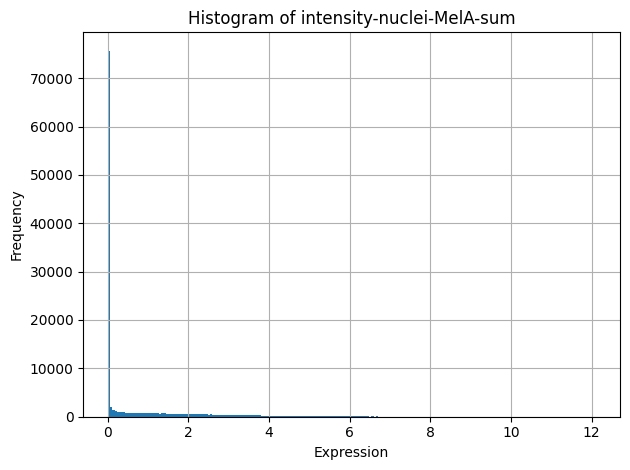

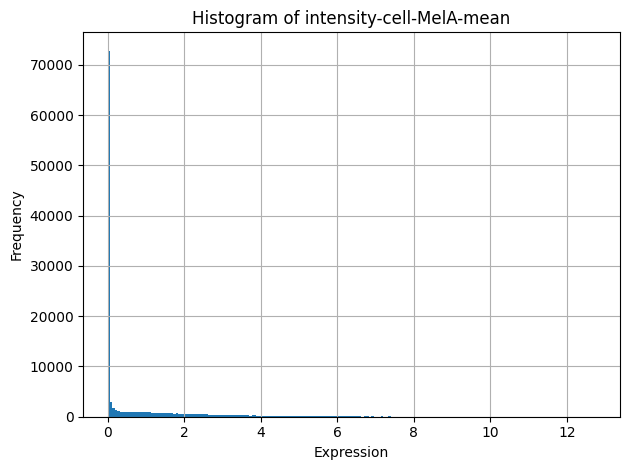

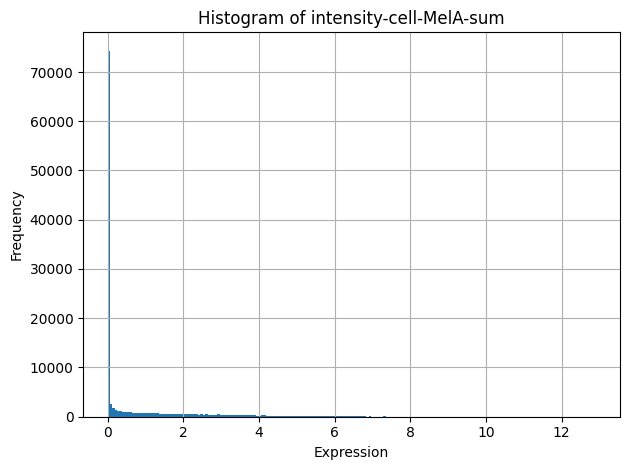

In [10]:
import matplotlib.pyplot as plt
import scanpy as sc

# Filter for features containing "Sox9"
sox9_features = [name for name in cellot_4i.var_names if "MelA" in name]

# Plot histograms for each feature
for feature in sox9_features:
    plt.figure()
    plt.hist(cellot_4i[:, feature].X.A.flatten() if hasattr(cellot_4i[:, feature].X, 'A') else cellot_4i[:, feature].X.flatten(), bins=200)
    plt.title(f'Histogram of {feature}')
    plt.xlabel('Expression')
    plt.ylabel('Frequency')
    plt.grid(True)
    plt.tight_layout()
    plt.show()


In [58]:
import numpy as np

# Identify features related to Sox in the cell and nucleus
sox_cell_features = [name for name in cellot_4i.var_names if "Sox" in name and "cell" in name and 'mean' in name]
sox_nuc_features = [name for name in cellot_4i.var_names if "Sox" in name and "nuclei" in name and 'mean' in name]

# Define thresholds for "expression" (can be adjusted if needed)
# Here we just check for any non-zero value
sox_cell_expr = np.any(cellot_4i[:, sox_cell_features].X.toarray() > 0.05, axis=1) if sox_cell_features else np.zeros(cellot_4i.n_obs, dtype=bool)
sox_nuc_expr = np.any(cellot_4i[:, sox_nuc_features].X.toarray() > 0.05, axis=1) if sox_nuc_features else np.zeros(cellot_4i.n_obs, dtype=bool)

# Add to obs
cellot_4i.obs["Sox+_cell"] = sox_cell_expr
cellot_4i.obs["Sox+_nuc"] = sox_nuc_expr


In [59]:
cellot_4i

AnnData object with n_obs × n_vars = 119479 × 78
    obs: 'drug', 'Sox+_cell', 'Sox+_nuc', 'MelA+_cell', 'MelA+_nuc', 'MelA+', 'Sox+'
    var: 'cell_part', 'measurement', 'stat', 'feature', 'original'
    uns: 'source'

In [60]:
cellot_4i.obs[["Sox+_cell", "Sox+_nuc"]].sum(axis=1).value_counts()

2    67946
0    50231
1     1302
Name: count, dtype: int64

In [61]:
cellot_4i.obs["Sox+"] = cellot_4i.obs[["Sox+_cell", "Sox+_nuc"]].sum(axis=1) == 2

In [66]:
import numpy as np

# Identify features related to Sox in the cell and nucleus
sox_cell_features = [name for name in cellot_4i.var_names if "MelA" in name and "cell" in name and 'mean' in name]
sox_nuc_features = [name for name in cellot_4i.var_names if "MelA" in name and "nuclei" in name and 'mean' in name]

# Define thresholds for "expression" (can be adjusted if needed)
# Here we just check for any non-zero value
sox_cell_expr = np.any(cellot_4i[:, sox_cell_features].X.toarray() > 0.01, axis=1) if sox_cell_features else np.zeros(cellot_4i.n_obs, dtype=bool)
sox_nuc_expr = np.any(cellot_4i[:, sox_nuc_features].X.toarray() > 0.01, axis=1) if sox_nuc_features else np.zeros(cellot_4i.n_obs, dtype=bool)

# Add to obs
cellot_4i.obs["MelA+_cell"] = sox_cell_expr
cellot_4i.obs["MelA+_nuc"] = sox_nuc_expr


In [78]:
cellot_4i.obs[["MelA+_cell", "MelA+_nuc"]].sum(axis=1).value_counts()

0    52140
2    44727
1     8541
Name: count, dtype: int64

Problem: arbitrary threshold used. How could we validate/defend this threshold? --> we expect a rather equal mixture, so the threshold has to be in a range that results in two comparably large classes and low numbers in between (class 1).

In [79]:
cellot_4i.obs["MelA+"] = cellot_4i.obs[["MelA+_cell", "MelA+_nuc"]].sum(axis=1) == 2

In [80]:
cellot_4i.obs[["MelA+", "Sox+"]].sum(axis=1).value_counts()

1    105408
Name: count, dtype: int64

Nice, seems to split rather well.

In [81]:
cellot_4i = cellot_4i[cellot_4i.obs[["MelA+", "Sox+"]].sum(axis=1) == 1,:]

In [82]:
cellot_4i.obs['cell_line'] = cellot_4i.obs['MelA+'].map(lambda x: 'MelA+' if x else 'Sox9+')

/tmp/ipykernel_2599978/3101911782.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  cellot_4i.obs['cell_line'] = cellot_4i.obs['MelA+'].map(lambda x: 'MelA+' if x else 'Sox9+')


In [83]:
cellot_4i.obs['cell_line'].value_counts()

cell_line
Sox9+    60681
MelA+    44727
Name: count, dtype: int64

/lustre/groups/ml01/workspace/lea.zimmermann/software/miniconda3/envs/mmfm/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:438: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  warn(msg, FutureWarning)
/lustre/groups/ml01/workspace/lea.zimmermann/software/miniconda3/envs/mmfm/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:379: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = X_pca


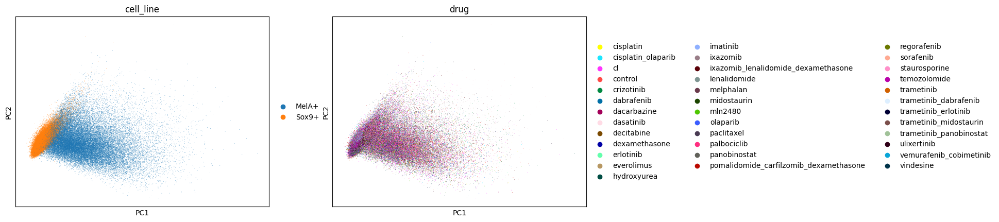

In [88]:
cellot_4i = cellot_4i[cellot_4i.obs['drug'] != 'sec.abcl',:]

sc.pp.pca(cellot_4i, n_comps=10, use_highly_variable=False)
sc.pl.pca(cellot_4i, color=['cell_line', 'drug'])

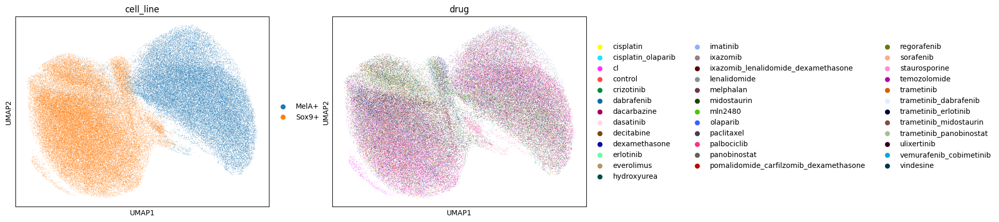

In [89]:
sc.pp.neighbors(cellot_4i)
sc.tl.umap(cellot_4i)
sc.pl.umap(cellot_4i, color=['cell_line', 'drug'])

/lustre/groups/ml01/workspace/lea.zimmermann/software/miniconda3/envs/mmfm/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:438: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  warn(msg, FutureWarning)
/lustre/groups/ml01/workspace/lea.zimmermann/software/miniconda3/envs/mmfm/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:379: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = X_pca


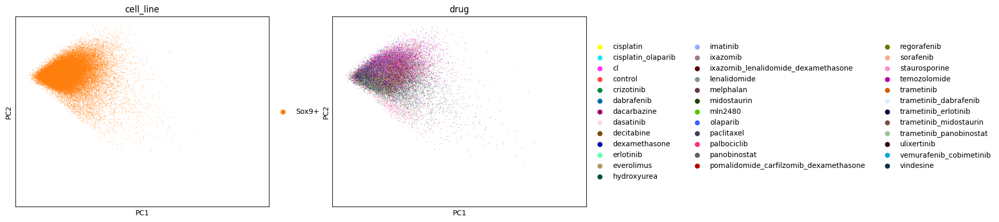

In [90]:
sox = cellot_4i[cellot_4i.obs['cell_line'] == 'Sox9+',:]
mela = cellot_4i[cellot_4i.obs['cell_line'] == 'MelA+',:]

sc.pp.pca(sox, n_comps=10, use_highly_variable=False)
sc.pl.pca(sox, color=['cell_line', 'drug'])

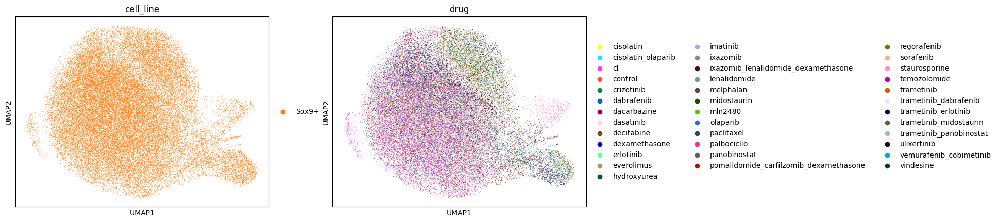

In [91]:
sc.pp.neighbors(sox)
sc.tl.umap(sox)
sc.pl.umap(sox, color=['cell_line', 'drug'])

/lustre/groups/ml01/workspace/lea.zimmermann/software/miniconda3/envs/mmfm/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:438: FutureWarning: Argument `use_highly_variable` is deprecated, consider using the mask argument. Use_highly_variable=True can be called through mask_var="highly_variable". Use_highly_variable=False can be called through mask_var=None
  warn(msg, FutureWarning)
/lustre/groups/ml01/workspace/lea.zimmermann/software/miniconda3/envs/mmfm/lib/python3.12/site-packages/scanpy/preprocessing/_pca/__init__.py:379: ImplicitModificationWarning: Setting element `.obsm['X_pca']` of view, initializing view as actual.
  adata.obsm[key_obsm] = X_pca


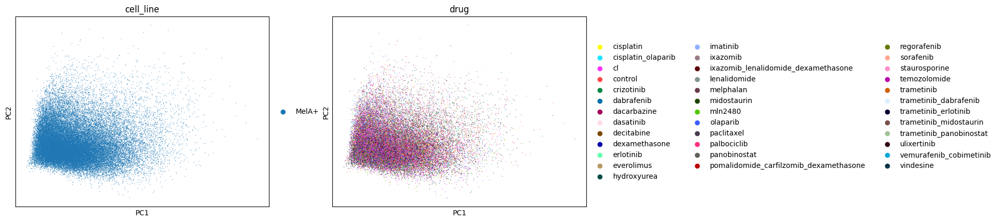

In [92]:
sc.pp.pca(mela, n_comps=10, use_highly_variable=False)
sc.pl.pca(mela, color=['cell_line', 'drug'])

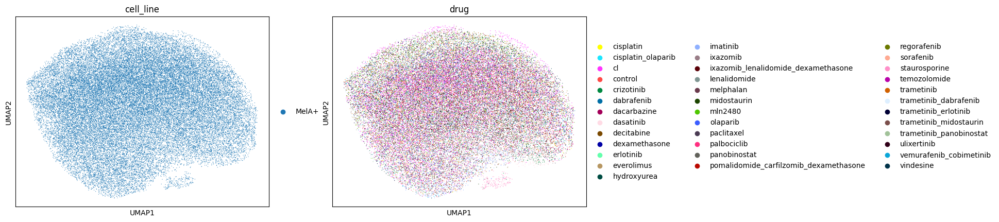

In [93]:
sc.pp.neighbors(mela)
sc.tl.umap(mela)
sc.pl.umap(mela, color=['cell_line', 'drug'])

In [94]:
import pandas as pd
from sklearn.metrics import r2_score
import numpy as np

# Subset to control cells
control_mask = mela.obs["drug"] == "control"
control_means = mela[control_mask].X.mean(axis=0)

# Ensure control_means is 1D np array
control_means = np.asarray(control_means).flatten()

# Initialize results
r2_results = {}

# Iterate over each unique drug (excluding 'control')
for drug in mela.obs["drug"].unique():
    if drug == "control":
        continue

    # Get mean profile for this drug
    drug_mask = mela.obs["drug"] == drug
    drug_means = mela[drug_mask].X.mean(axis=0)
    drug_means = np.asarray(drug_means).flatten()

    # Compute R^2 score
    r2 = r2_score(control_means, drug_means)
    r2_results[drug] = r2

# Convert to DataFrame for display
r2_df = pd.DataFrame.from_dict(r2_results, orient="index", columns=["r2_score"]).sort_values("r2_score", ascending=False)
r2_df


,r2_score
decitabine,0.979852
lenalidomide,0.962616
melphalan,0.961272
olaparib,0.957132
cisplatin_olaparib,0.946109
cisplatin,0.935976
cl,0.932792
erlotinib,0.923267
dacarbazine,0.920048
dexamethasone,0.913598


In [95]:
control_mask = sox.obs["drug"] == "control"
control_means = sox[control_mask].X.mean(axis=0)

# Ensure control_means is 1D np array
control_means = np.asarray(control_means).flatten()

# Initialize results
r2_results = {}

# Iterate over each unique drug (excluding 'control')
for drug in sox.obs["drug"].unique():
    if drug == "control":
        continue

    # Get mean profile for this drug
    drug_mask = sox.obs["drug"] == drug
    drug_means = sox[drug_mask].X.mean(axis=0)
    drug_means = np.asarray(drug_means).flatten()

    # Compute R^2 score
    r2 = r2_score(control_means, drug_means)
    r2_results[drug] = r2

# Convert to DataFrame for display
r2_df = pd.DataFrame.from_dict(r2_results, orient="index", columns=["r2_score"]).sort_values("r2_score", ascending=False)
r2_df


,r2_score
lenalidomide,0.970300
decitabine,0.963662
dacarbazine,0.960921
cisplatin,0.953462
melphalan,0.953032
olaparib,0.942091
cl,0.941114
erlotinib,0.939426
palbociclib,0.921180
temozolomide,0.893860
